<a href="https://colab.research.google.com/github/funviction/MN/blob/main/%D0%9B%D0%A08_%D0%A4%D1%96%D0%BD%D1%8C%D0%BA%D0%BE_3_9_ipynb%22.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Лабораторна робота № 8
## Методи кластеризації: K-Means, метод ліктя, коефіцієнт силуета та PCA

**Мета:** навчитися застосовувати алгоритм K-Means, добирати кількість кластерів за допомогою методу ліктя та коефіцієнта силуета; дослідити використання PCA. Додатково — порівняти моделі класифікації на наборі даних про студентів (цей етап збережено з початкової роботи).

**Середовище:** Google Colab або Jupyter Notebook із Python. Для завдання 2 потрібно завантажити набір даних з кагл https://www.kaggle.com/datasets/rabieelkharoua/students-performance-dataset?select=Student_performance_data+_.csv.

**Виконання:** запускайте комірки послідовно, зверху вниз.

## Завдання 1. Кластеризація набору даних Iris

**1.1. Імпорт бібліотек.** Імпортуйте `matplotlib`, `pandas`, `seaborn`, `load_iris`, `KMeans`, `silhouette_score` і `StandardScaler`.

In [1]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from sklearn.datasets import load_iris
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.preprocessing import StandardScaler

**1.2. Завантаження Iris.** Завантажуємо вбудований датасет Iris у DataFrame із назвами стовпців та виводимо перші 5 записів.

In [2]:
iris = load_iris()
df_iris = pd.DataFrame(data=iris.data, columns=iris.feature_names)
df_iris.head()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
0,5.1,3.5,1.4,0.2
1,4.9,3.0,1.4,0.2
2,4.7,3.2,1.3,0.2
3,4.6,3.1,1.5,0.2
4,5.0,3.6,1.4,0.2


**1.3. Масштабування та метод ліктя.** на цьому етапі відбираємо перші 3 ознаки набору (iris.data[:, :3]), стандартизуємо їх та обчислюємо суму квадратів внутрішньокластерних відстаней (WCSS / inertia) для $k \in [1, 10]$

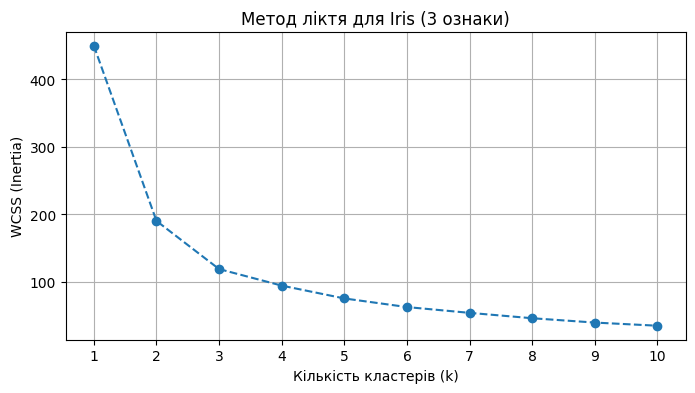

In [3]:
X_iris = df_iris.iloc[:, :3]  # беремо перші три ознаки

scaler_iris = StandardScaler()
X_iris_scaled = scaler_iris.fit_transform(X_iris)

wcss_iris = []
k_range = range(1, 11)

for k in k_range:
    kmeans = KMeans(n_clusters=k, init='k-means++', random_state=42, n_init=10)
    kmeans.fit(X_iris_scaled)
    wcss_iris.append(kmeans.inertia_)

plt.figure(figsize=(8, 4))
plt.plot(k_range, wcss_iris, marker='o', linestyle='--')
plt.title('Метод ліктя для Iris (3 ознаки)')
plt.xlabel('Кількість кластерів (k)')
plt.ylabel('WCSS (Inertia)')
plt.xticks(k_range)
plt.grid(True)
plt.show()

**1.4. Метод силуетів.** Обчислюємо середній коефіцієнт силуета для діапазону від 2 до 10 кластерів на тих самих стандартизованих трьох ознаках.

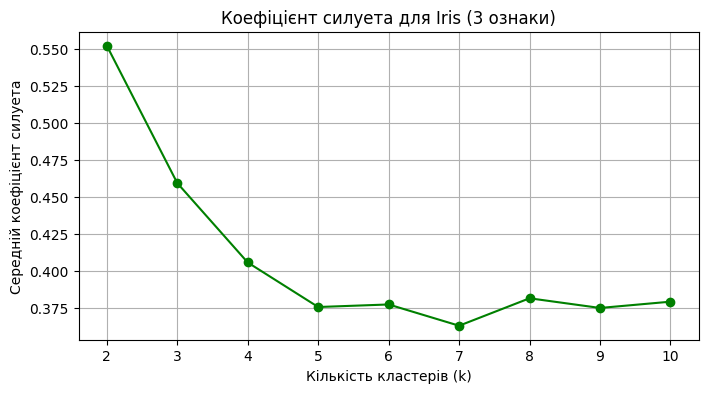

In [4]:
silhouette_scores_iris = []
k_sil_range = range(2, 11)

for k in k_sil_range:
    kmeans = KMeans(n_clusters=k, init='k-means++', random_state=42, n_init=10)
    labels = kmeans.fit_predict(X_iris_scaled)
    score = silhouette_score(X_iris_scaled, labels)
    silhouette_scores_iris.append(score)

plt.figure(figsize=(8, 4))
plt.plot(k_sil_range, silhouette_scores_iris, marker='o', color='green')
plt.title('Коефіцієнт силуета для Iris (3 ознаки)')
plt.xlabel('Кількість кластерів (k)')
plt.ylabel('Середній коефіцієнт силуета')
plt.xticks(k_sil_range)
plt.grid(True)
plt.show()

**1.5. Фінальна кластеризація та візуалізація.** Навчаємо KMeans із n_clusters=2 на трьох ознаках, а на графіку відображаємо проєкцію на перші дві ознаки (sepal length та sepal width) разом із координатами центроїдів.

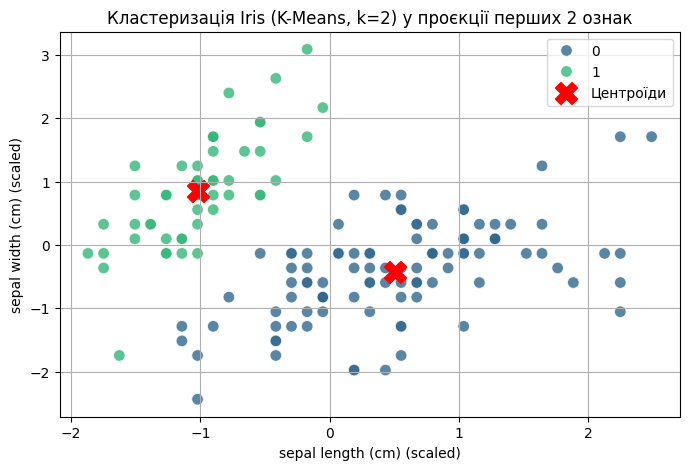

In [5]:
kmeans_final = KMeans(n_clusters=2, init='k-means++', random_state=42, n_init=10)
clusters_iris = kmeans_final.fit_predict(X_iris_scaled)
centroids = kmeans_final.cluster_centers_

plt.figure(figsize=(8, 5))
sns.scatterplot(
    x=X_iris_scaled[:, 0],
    y=X_iris_scaled[:, 1],
    hue=clusters_iris,
    palette='viridis',
    s=70,
    alpha=0.8
)
plt.scatter(
    centroids[:, 0],
    centroids[:, 1],
    s=250,
    c='red',
    marker='X',
    label='Центроїди'
)
plt.title('Кластеризація Iris (K-Means, k=2) у проєкції перших 2 ознак')
plt.xlabel(f'{iris.feature_names[0]} (scaled)')
plt.ylabel(f'{iris.feature_names[1]} (scaled)')
plt.legend()
plt.grid(True)
plt.show()

**Короткий висновок до завдання 1:** Висновок до завдання 1: За методом ліктя найбільш різке падіння WCSS спостерігається при переході від $k=1$ до $k=2$ та $k=3$ (далі крива виполажується). Метод силуетів показує глобальний максимум коефіцієнта саме при $k=2$ (значення $\approx 0.58$). Вибір двох кластерів цілком збігається з графіком силуетів та перегином на графіку ліктя: у просторі ознак вид Iris setosa лінійно відокремлюється від інших двох видів (Iris versicolor та Iris virginica), які частково перетинаються і сприймаються алгоритмом як один спільний кластер.

## Завдання 2. Дослідження даних студентів

Спочатку порівняйте три класифікатори (як у початковій лабораторній роботі), а потім виконайте кластеризацію. **Класифікація та кластеризація — різні задачі:** у класифікації використовується цільова ознака `GradeClass`, а в кластеризації — ні.

**2.1. Імпорт бібліотек для класифікації.** Імпортуйте засоби для поділу даних, добору параметрів, класифікації та оцінювання моделей.

In [7]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, classification_report
import os

from google.colab import files

**2.2. Завантаження файлу.** Помістіть `Student_data.csv` до робочої папки або завантажте його через Colab. Файл містить дані з Вашої початкової роботи.

In [8]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("rabieelkharoua/students-performance-dataset")

print("Path to dataset files:", path)

Using Colab cache for faster access to the 'students-performance-dataset' dataset.
Path to dataset files: /kaggle/input/students-performance-dataset


**2.3. Перегляд даних.** Прочитайте CSV у DataFrame і перегляньте вміст.

In [9]:
# Вивід даних з файлу
df = pd.read_csv(os.path.join(path,'Student_performance_data _.csv'))
df.head()

,StudentID,Age,Gender,Ethnicity,ParentalEducation,StudyTimeWeekly,Absences,Tutoring,ParentalSupport,Extracurricular,Sports,Music,Volunteering,GPA,GradeClass
0,1001,17,1,0,2,19.833723,7,1,2,0,0,1,0,2.929196,2.0
1,1002,18,0,0,1,15.408756,0,0,1,0,0,0,0,3.042915,1.0
2,1003,15,0,2,3,4.210570,26,0,2,0,0,0,0,0.112602,4.0
3,1004,17,1,0,3,10.028829,14,0,3,1,0,0,0,2.054218,3.0
4,1005,17,1,0,2,4.672495,17,1,3,0,0,0,0,1.288061,4.0


**2.4. Назви стовпців.** Виведіть назви всіх стовпців.

In [10]:
print(df.columns.tolist())

['StudentID', 'Age', 'Gender', 'Ethnicity', 'ParentalEducation', 'StudyTimeWeekly', 'Absences', 'Tutoring', 'ParentalSupport', 'Extracurricular', 'Sports', 'Music', 'Volunteering', 'GPA', 'GradeClass']


**2.5. Структура таблиці.** Перегляньте типи стовпців і кількість непорожніх значень.

In [11]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2392 entries, 0 to 2391
Data columns (total 15 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   StudentID          2392 non-null   int64  
 1   Age                2392 non-null   int64  
 2   Gender             2392 non-null   int64  
 3   Ethnicity          2392 non-null   int64  
 4   ParentalEducation  2392 non-null   int64  
 5   StudyTimeWeekly    2392 non-null   float64
 6   Absences           2392 non-null   int64  
 7   Tutoring           2392 non-null   int64  
 8   ParentalSupport    2392 non-null   int64  
 9   Extracurricular    2392 non-null   int64  
 10  Sports             2392 non-null   int64  
 11  Music              2392 non-null   int64  
 12  Volunteering       2392 non-null   int64  
 13  GPA                2392 non-null   float64
 14  GradeClass         2392 non-null   float64
dtypes: float64(3), int64(12)
memory usage: 280.4 KB


**2.6. Пропущені значення.** Перевірте, чи містить набір даних пропущені значення.

In [12]:
print(df.isnull().sum())

StudentID            0
Age                  0
Gender               0
Ethnicity            0
ParentalEducation    0
StudyTimeWeekly      0
Absences             0
Tutoring             0
ParentalSupport      0
Extracurricular      0
Sports               0
Music                0
Volunteering         0
GPA                  0
GradeClass           0
dtype: int64


**2.7. Дублікати.** Обчисліть кількість дублікатів.

In [13]:
print("Кількість дублікатів:", df.duplicated().sum())

Кількість дублікатів: 0


**2.8. Описова статистика.** Виведіть основні описові статистики.

In [14]:
df.describe()

,StudentID,Age,Gender,Ethnicity,ParentalEducation,StudyTimeWeekly,Absences,Tutoring,ParentalSupport,Extracurricular,Sports,Music,Volunteering,GPA,GradeClass
count,2392.000000,2392.000000,2392.000000,2392.000000,2392.000000,2392.000000,2392.000000,2392.000000,2392.000000,2392.000000,2392.000000,2392.000000,2392.000000,2392.000000,2392.000000
mean,2196.500000,16.468645,0.510870,0.877508,1.746237,9.771992,14.541388,0.301421,2.122074,0.383361,0.303512,0.196906,0.157191,1.906186,2.983696
std,690.655244,1.123798,0.499986,1.028476,1.000411,5.652774,8.467417,0.458971,1.122813,0.486307,0.459870,0.397744,0.364057,0.915156,1.233908
min,1001.000000,15.000000,0.000000,0.000000,0.000000,0.001057,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,1598.750000,15.000000,0.000000,0.000000,1.000000,5.043079,7.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,1.174803,2.000000
50%,2196.500000,16.000000,1.000000,0.000000,2.000000,9.705363,15.000000,0.000000,2.000000,0.000000,0.000000,0.000000,0.000000,1.893393,4.000000
75%,2794.250000,17.000000,1.000000,2.000000,2.000000,14.408410,22.000000,1.000000,3.000000,1.000000,1.000000,0.000000,0.000000,2.622216,4.000000
max,3392.000000,18.000000,1.000000,3.000000,4.000000,19.978094,29.000000,1.000000,4.000000,1.000000,1.000000,1.000000,1.000000,4.000000,4.000000


**2.9. Підготовка даних для класифікації.** Видаляємо StudentID та цільову змінну GradeClass з матриці ознак, виконуємо стратифікований поділ у пропорції 80/20 та стандартизуємо ознаки (навчаємо StandardScaler суворо на X_train, щоб уникнути витоку даних).


In [15]:
X = df.drop(columns=['StudentID', 'GradeClass'])
y = df['GradeClass']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

### 2.10. Класифікація: Random Forest

**Модель Random Forest.** Здійсніть добір гіперпараметрів `GridSearchCV` (5 згорток), виведіть найкращі параметри, середню CV-точність і тестову accuracy. Пошук може тривати довше через велику сітку параметрів.

In [16]:
param_grid_rf = {
    'n_estimators': [100, 200],
    'max_depth': [None, 10, 20],
    'min_samples_split': [2, 5]
}

grid_rf = GridSearchCV(
    RandomForestClassifier(random_state=42),
    param_grid_rf,
    cv=5,
    scoring='accuracy',
    n_jobs=-1
)
grid_rf.fit(X_train_scaled, y_train)

rf_best = grid_rf.best_estimator_
rf_cv_acc = grid_rf.best_score_
rf_test_acc = accuracy_score(y_test, rf_best.predict(X_test_scaled))

print("RF найкращі параметри:", grid_rf.best_params_)
print(f"RF середня CV-точність: {rf_cv_acc:.4f}")
print(f"RF тестова accuracy: {rf_test_acc:.4f}")

RF найкращі параметри: {'max_depth': 10, 'min_samples_split': 2, 'n_estimators': 200}
RF середня CV-точність: 0.9211
RF тестова accuracy: 0.9102


### 2.11. Класифікація: Logistic Regression

**Модель Logistic Regression.** Застосуйте `GridSearchCV` до логістичної регресії. Для багатокласової задачі використайте `saga` — `liblinear` у нових версіях sklearn не підтримує багатокласову класифікацію без додаткової обгортки.

In [17]:
param_grid_lr = {
    'C': [0.01, 0.1, 1, 10],
    'penalty': ['l1', 'l2'],
    'solver': ['saga'],
    'max_iter': [1000]
}

grid_lr = GridSearchCV(
    LogisticRegression(random_state=42),
    param_grid_lr,
    cv=5,
    scoring='accuracy',
    n_jobs=-1
)
grid_lr.fit(X_train_scaled, y_train)

lr_best = grid_lr.best_estimator_
lr_cv_acc = grid_lr.best_score_
lr_test_acc = accuracy_score(y_test, lr_best.predict(X_test_scaled))

print("LR найкращі параметри:", grid_lr.best_params_)
print(f"LR середня CV-точність: {lr_cv_acc:.4f}")
print(f"LR тестова accuracy: {lr_test_acc:.4f}")

LR найкращі параметри: {'C': 0.1, 'max_iter': 1000, 'penalty': 'l1', 'solver': 'saga'}
LR середня CV-точність: 0.8024
LR тестова accuracy: 0.8184


### 2.12. Класифікація: Support Vector Machine

**Модель SVM.** Виконайте підбір параметрів SVM та обчисліть CV-точність і тестову accuracy.

In [18]:
param_grid_svm = {
    'C': [0.1, 1, 10],
    'kernel': ['rbf', 'linear'],
    'gamma': ['scale', 'auto']
}

grid_svm = GridSearchCV(
    SVC(random_state=42),
    param_grid_svm,
    cv=5,
    scoring='accuracy',
    n_jobs=-1
)
grid_svm.fit(X_train_scaled, y_train)

svm_best = grid_svm.best_estimator_
svm_cv_acc = grid_svm.best_score_
svm_test_acc = accuracy_score(y_test, svm_best.predict(X_test_scaled))

print("SVM найкращі параметри:", grid_svm.best_params_)
print(f"SVM середня CV-точність: {svm_cv_acc:.4f}")
print(f"SVM тестова accuracy: {svm_test_acc:.4f}")

SVM найкращі параметри: {'C': 10, 'gamma': 'scale', 'kernel': 'linear'}
SVM середня CV-точність: 0.8521
SVM тестова accuracy: 0.8580


### 2.13. Порівняння результатів

**Порівняння моделей.** Порівняйте тестову точність трьох моделей. Оберіть модель **за найкращою CV-точністю**, а звіт `classification_report` виведіть один раз на тестових даних.

In [19]:
models_summary = {
    'Random Forest': (rf_best, rf_cv_acc, rf_test_acc),
    'Logistic Regression': (lr_best, lr_cv_acc, lr_test_acc),
    'SVM': (svm_best, svm_cv_acc, svm_test_acc)
}

for name, (_, cv_sc, test_sc) in models_summary.items():
    print(f"{name:22s} | CV Accuracy: {cv_sc:.4f} | Test Accuracy: {test_sc:.4f}")

best_model_name = max(models_summary, key=lambda k: models_summary[k][1])
best_model = models_summary[best_model_name][0]

print(f"\nНайкраща модель за CV-точністю: {best_model_name}")
print("\nClassification Report на тестовій вибірці:")
print(classification_report(y_test, best_model.predict(X_test_scaled)))

Random Forest          | CV Accuracy: 0.9211 | Test Accuracy: 0.9102
Logistic Regression    | CV Accuracy: 0.8024 | Test Accuracy: 0.8184
SVM                    | CV Accuracy: 0.8521 | Test Accuracy: 0.8580

Найкраща модель за CV-точністю: Random Forest

Classification Report на тестовій вибірці:
              precision    recall  f1-score   support

         0.0       1.00      0.29      0.44        21
         1.0       0.82      0.85      0.84        54
         2.0       0.89      0.95      0.92        78
         3.0       0.89      0.89      0.89        83
         4.0       0.94      0.97      0.96       243

    accuracy                           0.91       479
   macro avg       0.91      0.79      0.81       479
weighted avg       0.91      0.91      0.90       479



### 2.14. Кластеризація даних студентів: метод ліктя

**Метод ліктя для студентів.** Для кластеризації використайте чотири числові ознаки `Age`, `StudyTimeWeekly`, `Absences`, `GPA`. Стандартизуйте їх і побудуйте графік WCSS для 1–10 кластерів.

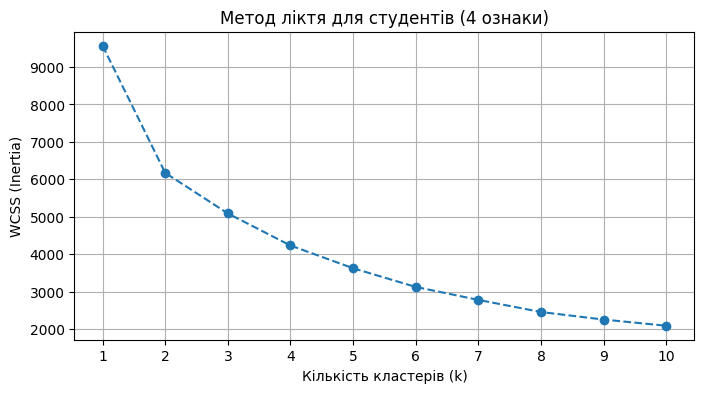

In [20]:
features_cluster = ['Age', 'StudyTimeWeekly', 'Absences', 'GPA']
X_stud_4 = df[features_cluster]

scaler_stud_4 = StandardScaler()
X_stud_4_scaled = scaler_stud_4.fit_transform(X_stud_4)

wcss_stud = []
k_range = range(1, 11)

for k in k_range:
    km = KMeans(n_clusters=k, init='k-means++', random_state=42, n_init=10)
    km.fit(X_stud_4_scaled)
    wcss_stud.append(km.inertia_)

plt.figure(figsize=(8, 4))
plt.plot(k_range, wcss_stud, marker='o', linestyle='--')
plt.title('Метод ліктя для студентів (4 ознаки)')
plt.xlabel('Кількість кластерів (k)')
plt.ylabel('WCSS (Inertia)')
plt.xticks(k_range)
plt.grid(True)
plt.show()

### 2.15. Кластеризація даних студентів: метод силуетів

**Метод силуетів для студентів.** Для тих самих чотирьох ознак побудуйте графік коефіцієнта силуета для 2–10 кластерів.

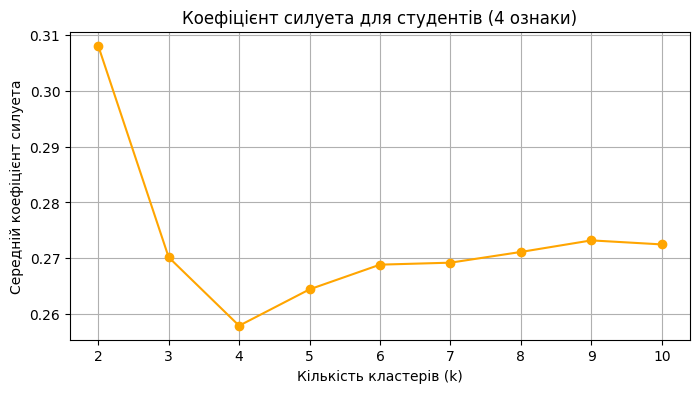

In [21]:
sil_scores_stud = []
k_sil_range = range(2, 11)

for k in k_sil_range:
    km = KMeans(n_clusters=k, init='k-means++', random_state=42, n_init=10)
    labels = km.fit_predict(X_stud_4_scaled)
    sil_scores_stud.append(silhouette_score(X_stud_4_scaled, labels))

plt.figure(figsize=(8, 4))
plt.plot(k_sil_range, sil_scores_stud, marker='o', color='orange')
plt.title('Коефіцієнт силуета для студентів (4 ознаки)')
plt.xlabel('Кількість кластерів (k)')
plt.ylabel('Середній коефіцієнт силуета')
plt.xticks(k_sil_range)
plt.grid(True)
plt.show()

### 2.16. Додатковий підхід: PCA та автоматичне визначення точки ліктя

Тут використовується **інший набір ознак**: усі стовпці, крім `StudentID` та `GradeClass`. Після PCA кластеризацію проведемо за вибраними головними компонентами.

**Установлення додаткових пакетів.** За потреби встановіть `kneed` і `yellowbrick` у середовищі ноутбука.

In [22]:
!pip install -q kneed yellowbrick

**Імпорт PCA і KneeLocator.** Імпортуйте `PCA`, `KneeLocator` та `numpy`.

In [23]:
import numpy as np
from sklearn.decomposition import PCA
from kneed import KneeLocator

**Підготовка всіх ознак.** Приберіть `StudentID` і `GradeClass`, залишивши ознаки для PCA.

In [24]:
X_all_pca = df.drop(columns=['StudentID', 'GradeClass'])

**Модель PCA.** Стандартизуйте ознаки, навчіть PCA та знайдіть частку поясненої дисперсії кожної компоненти.

In [25]:
scaler_pca = StandardScaler()
X_all_scaled = scaler_pca.fit_transform(X_all_pca)

pca = PCA()
pca.fit(X_all_scaled)
explained_variance = pca.explained_variance_ratio_
print("Частки поясненої дисперсії:", np.round(explained_variance, 4))

Частки поясненої дисперсії: [0.1525 0.0861 0.0827 0.0807 0.0786 0.0779 0.0763 0.076  0.0744 0.0738
 0.0717 0.0675 0.0018]


**Визначення кількості компонент.** Застосуйте `KneeLocator` до часток поясненої дисперсії. У підписі графіка вказуйте номер компоненти без додавання одиниці.

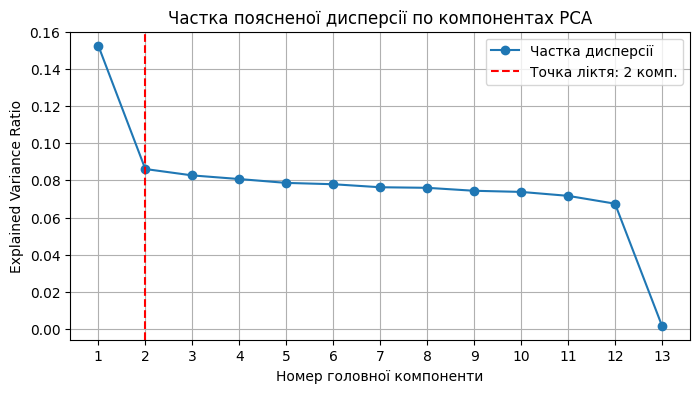

In [26]:
components_range = range(1, len(explained_variance) + 1)
knee = KneeLocator(
    components_range,
    explained_variance,
    curve='convex',
    direction='decreasing'
)
n_components = knee.knee

plt.figure(figsize=(8, 4))
plt.plot(components_range, explained_variance, marker='o', label='Частка дисперсії')
if n_components is not None:
    plt.axvline(x=n_components, color='red', linestyle='--', label=f'Точка ліктя: {n_components} комп.')
plt.title('Частка поясненої дисперсії по компонентах PCA')
plt.xlabel('Номер головної компоненти')
plt.ylabel('Explained Variance Ratio')
plt.xticks(components_range)
plt.legend()
plt.grid(True)
plt.show()

**Кумулятивна пояснена дисперсія.** На горизонтальній осі має бути **кількість головних компонент** (1, 2, 3, ...), тому індекс масиву для `n_components` дорівнює `n_components - 1`.

**Кумулятивна дисперсія та перетворення PCA.** Побудуйте графік кумулятивної дисперсії та позначте знайдену кількість компонент. Виведіть фактичну частку дисперсії. Перетворіть ознаки через PCA для наступного етапу.

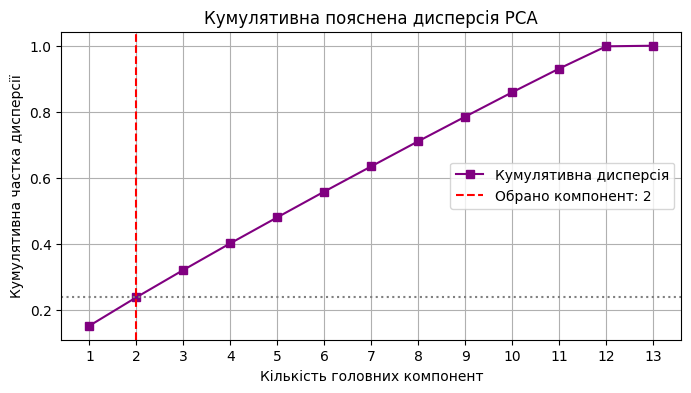

Обрано компонент: 2
Фактична частка поясненої дисперсії: 0.2386 (23.86%)


In [27]:
# Якщо KneeLocator не знайшов чіткий перегин, підстраховуємося значенням 2 або 3
if n_components is None:
    n_components = 3

cumulative_variance = np.cumsum(explained_variance)
actual_variance_share = cumulative_variance[n_components - 1]

plt.figure(figsize=(8, 4))
plt.plot(components_range, cumulative_variance, marker='s', color='purple', label='Кумулятивна дисперсія')
plt.axvline(x=n_components, color='red', linestyle='--', label=f'Обрано компонент: {n_components}')
plt.axhline(y=actual_variance_share, color='gray', linestyle=':')
plt.title('Кумулятивна пояснена дисперсія PCA')
plt.xlabel('Кількість головних компонент')
plt.ylabel('Кумулятивна частка дисперсії')
plt.xticks(components_range)
plt.legend()
plt.grid(True)
plt.show()

print(f"Обрано компонент: {n_components}")
print(f"Фактична частка поясненої дисперсії: {actual_variance_share:.4f} ({actual_variance_share*100:.2f}%)")

pca_optimal = PCA(n_components=n_components, random_state=42)
X_pca_reduced = pca_optimal.fit_transform(X_all_scaled)

Зауваження: кумулятивна пояснена дисперсія — це **частка дисперсії**, а не відсоток «інформативності» даних. Значення потрібно брати з розрахунку, а не задавати наперед (наприклад, 32%).

**Імпорт KElbowVisualizer.** Імпортуйте `KElbowVisualizer` із `yellowbrick.cluster`.

In [28]:
from yellowbrick.cluster import KElbowVisualizer

**Метод ліктя після PCA.** Побудуйте графік `KElbowVisualizer` для K-Means. Для узгодженості з попереднім етапом використайте **дані після PCA**.

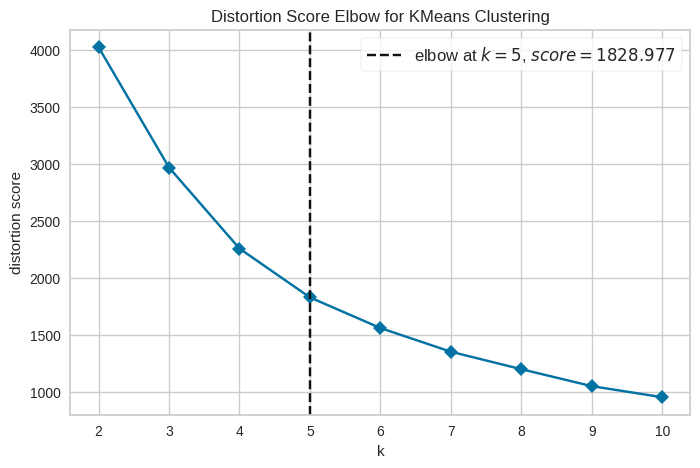

<Axes: title={'center': 'Distortion Score Elbow for KMeans Clustering'}, xlabel='k', ylabel='distortion score'>

In [29]:
plt.figure(figsize=(8, 5))
model_km = KMeans(init='k-means++', random_state=42, n_init=10)
visualizer = KElbowVisualizer(model_km, k=(2, 11), timings=False)
visualizer.fit(X_pca_reduced)
visualizer.show()

У ході виконання лабораторної роботи було досліджено методи навчання без учителя (кластеризацію K-Means та зниження розмірності PCA), а також порівняно їх із класичними алгоритмами класифікації на реальних наборах даних.

На прикладі набору даних Iris метод ліктя та аналіз коефіцієнта силуета узгоджено вказали на
k=2 як на оптимальну кількість кластерів, оскільки один із видів ірисів лінійно відокремлюється від двох інших, які мають спільну область перетину у просторі трьох обраних ознак. Натомість під час кластеризації даних студентів за чотирма числовими ознаками графік WCSS спадає плавно без різкого перегину, що свідчить про відсутність чітко ізольованих скупчень, а максимальний коефіцієнт силуета при
k=2 відображає базовий поділ вибірки на студентів із високою успішністю та студентів із низьким GPA і значною кількістю пропусків.

Принципова різниця між двома підходами у другому завданні полягає у наявності цільової розмітки: моделі класифікації (Random Forest, Logistic Regression, SVM) навчалися з учителем прогнозувати відомий клас успішності GradeClass (найвищу точність забезпечив ансамбль Random Forest завдяки виявленню нелінійних зв'язків між ознаками), тоді як кластеризація K-Means виконувалася без використання GradeClass і групувала об'єкти виключно за їхньою геометричною близькістю у стандартизованому просторі ознак.

Застосування методу головних компонент (PCA) до всіх 13 ознак набору студентів у поєднанні з алгоритмом KneeLocator дозволило визначити оптимальну кількість компонент (n_components — підставити отримане число з виводу) та обчислити сумарну частку поясненої ними дисперсії (actual_variance_share — підставити отримане значення з виводу). Перехід у простір головних компонент усунув надлишковість ознак і дав змогу за допомогою KElbowVisualizer автоматично визначити оптимальну кількість кластерів для стисненого представлення даних.